# 08 — Intermediate MJJ VR working-point comparison (4μ)

**Scope:** **Intermediate MJJ VR: 150 ≤ MJJ < 300 GeV**, with
**0≤partner isolation<0.5**. Evaluate **PP and PD together** and show the
same selected WPs in **PP, PD, and DP**, in that order throughout.

The notebook starts with a **comprehensive five-WP summary table**, followed by
**eight comparison figures**: significance, two annotated full-range κ maps,
joint PP–PD closure, selected-WP yields/closure/contamination, and three 1D stability scans.
Detailed comparisons contain **only five WPs**.

The candidates are the **five highest nominal-SR MC significance ratios** in
the native local grid: iso={0.20,0.25,0.30,0.40}, |Δφ|={2.4,2.6,2.7,2.8}.
The reference (0.30,2.6) defines the significance normalization; it is shown as
a selected WP only if it belongs to the top five. It is not forced into the list.
PP/PD DATA closure is evaluated after this MC-only selection. DP does not select candidates.

**Nominal DATA is never accessed.** This focused version reads only the
validated notebook-04 tables; it does not reopen raw MC, signal, or DATA files.
Use **Restart → Run All** to reproduce the notebook.


In [1]:
from pathlib import Path
import sys

SIDM_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents) if p.name == 'sidm'), None)
if SIDM_DIR is None:
    raise RuntimeError('Run this notebook from inside the sidm repository.')
NOTEBOOK_DIR = SIDM_DIR / 'studies' / 'ABCD_finalize'
for folder in (SIDM_DIR.parent, NOTEBOOK_DIR):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import coffea.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from abcd_finalize_common import finalize_local_scan_build_vr2_focus_config as build_vr2_focus_config, finalize_local_scan_run_vr2_focus as run_vr2_focus, finalize_local_scan_vr2_focus_summary_tables as vr2_focus_summary_tables
from abcd_finalize_plots import finalize_local_scan_plots_make_vr2_focus_figures as make_vr2_focus_figures, finalize_local_scan_plots_vr2_focus_figure_definitions as vr2_focus_figure_definitions

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11, 'figure.max_open_warning': 0})
CONFIG = build_vr2_focus_config(NOTEBOOK_DIR, selection_mode='sr_significance', force_reference=False, topology='4mu')
CONFIG.update(scan_iso_limits=(0., 1.), scan_dphi_limits=(1., 3.))
OUTPUT_DIR = Path(CONFIG['output_dir'])


## 1. Comprehensive summary of the five selected WPs

For each of the **60 matching 4Mu signal hypotheses**, compute the known-background
Asimov $Z_A$ from the nominal DD MC SR A yields and divide by its value at (0.30,2.6).
Rank the local WPs by the median of those **per-hypothesis ratios**.
Production normalization and the existing ABCD definitions are unchanged.
Different signal hypotheses are not summed.

**A=low iso/high |Δφ|**, B=high/high, C=low/low, D=high/low.
LJ0 is the leading mu-LJ and LJ1 the subleading mu-LJ; retain this ordering in every displacement category.
The reference enters the normalization even when it is outside the displayed top five.
The five-row table contains SR signal/background yields, effective counts, κ and significance,
plus DATA A/B/C/D, BC/D, DATA/MC κ, contamination and statistical support in PP, PD and DP.
SR MC is the nominal DD selection used for ranking; PP/PD/DP are the Intermediate MJJ VR (150 ≤ MJJ < 300 GeV).
Signal yield and Z medians use the 60 matching hypotheses; ranges in brackets are
the **10th–90th model percentiles**, not statistical confidence intervals.
The DATA contamination gate still requires $S/B_{MC}<0.10$ in every ABCD region
for **all 120 distinct signal hypotheses**. Gate approval is not a closure-quality test.


In [2]:
results = run_vr2_focus(CONFIG)
tables = results['tables']
selected = tables['working_points'].sort_values('rank')
ranked = tables['ranking'].set_index('wp')
summary_tables = vr2_focus_summary_tables(results)
selected_table = summary_tables['display']
summary_numeric = summary_tables['numeric']

from html import escape
from IPython.display import HTML

summary_palette = ('#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00')
summary_colors = {}
summary_alternative = 0
for summary_point in selected.itertuples():
    if summary_point.is_reference:
        summary_colors[summary_point.wp] = '#666666'
    else:
        summary_colors[summary_point.wp] = summary_palette[summary_alternative]
        summary_alternative += 1
summary_css = """
<style>
#sidm-wp-summary {font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif;
  color: #1e293b; max-width: 100%; margin: 8px 0 16px;}
#sidm-wp-summary .summary-heading {display: flex; align-items: center; justify-content: space-between;
  gap: 12px; margin: 0 0 10px;}
#sidm-wp-summary .summary-heading strong {font-size: 17px; letter-spacing: -.2px;}
#sidm-wp-summary .summary-count {border: 1px solid #dbe4ee; border-radius: 99px;
  padding: 4px 10px; color: #64748b; font-size: 11px; white-space: nowrap;}
#sidm-wp-summary .summary-scroll {overflow-x: auto; border: 1px solid #dce4ee;
  border-radius: 12px; box-shadow: 0 3px 12px rgba(15, 23, 42, .045);}
#sidm-wp-summary table {border-collapse: separate; border-spacing: 0; width: 100%;
  min-width: 1060px; margin: 0; font-size: 11.5px; line-height: 1.4;}
#sidm-wp-summary th {background: #17263b; color: #f8fafc; text-align: left;
  padding: 12px 14px 10px; border-top: 3px solid #64748b; border-left: 1px solid #304155;
  font-size: 12px; font-weight: 650; white-space: nowrap;}
#sidm-wp-summary th:first-child {text-align: center; border-left: none;}
#sidm-wp-summary th:nth-child(2) {border-top-color: #38a3cf;}
#sidm-wp-summary th:nth-child(3) {border-top-color: #37b6a3;}
#sidm-wp-summary th:nth-child(4) {border-top-color: #ad8bd1;}
#sidm-wp-summary th:nth-child(5) {border-top-color: #e9b75c;}
#sidm-wp-summary .header-note {display: block; margin-top: 3px; color: #bdcbdc;
  font-size: 10px; font-weight: 400;}
#sidm-wp-summary td {background: #fff; vertical-align: top; padding: 11px 12px;
  border-top: 1px solid #e6ebf2; border-left: 1px solid #e6ebf2; min-width: 220px;}
#sidm-wp-summary tbody tr:nth-child(even) td {background: #f7f9fc;}
#sidm-wp-summary tbody tr:first-child td {border-top: none;}
#sidm-wp-summary td.wp-cell {min-width: 82px; width: 88px; padding: 12px 8px;
  border-left: none; vertical-align: middle; text-align: center;}
#sidm-wp-summary .wp-badge {display: inline-block; color: white; font-size: 13px;
  font-weight: 700; border-radius: 7px; padding: 5px 10px; margin-bottom: 7px;}
#sidm-wp-summary .cut-chip {display: block; color: #475569; font-size: 10.5px;
  white-space: nowrap; font-variant-numeric: tabular-nums; margin: 4px 0;}
#sidm-wp-summary .metric-row {display: flex; justify-content: space-between;
  align-items: baseline; column-gap: 9px; margin: 0 0 6px;}
#sidm-wp-summary .metric-row:last-child {margin-bottom: 0;}
#sidm-wp-summary .metric-label {color: #64748b; font-size: 10.5px; flex: 0 1 auto;}
#sidm-wp-summary .metric-value {color: #243449; text-align: right; font-weight: 550;
  white-space: nowrap; font-variant-numeric: tabular-nums; font-feature-settings: "tnum";}
#sidm-wp-summary .primary-metric {padding-top: 5px; margin-top: 4px;
  border-top: 1px solid #dfe7f0;}
#sidm-wp-summary .primary-metric .metric-label {color: #075985; font-weight: 650;}
#sidm-wp-summary .primary-metric .metric-value {color: #075985; font-weight: 750;}
#sidm-wp-summary .gate-tag {display: inline-block; border: 1px solid #d3deea;
  border-radius: 4px; padding: 0 4px; margin-left: 3px; background: #edf3f9;
  color: #36566f; font-size: 9.5px; font-weight: 600;}
#sidm-wp-summary .summary-note {font-size: 10.5px; line-height: 1.5; color: #64748b;
  margin: 9px 2px 0;}
</style>
"""
summary_notes = ('Selected cuts', '60 matching signal models',
                 '150 ≤ MJJ < 300 GeV · DATA / MC', '150 ≤ MJJ < 300 GeV · DATA / MC',
                 '150 ≤ MJJ < 300 GeV · DATA / MC')
summary_headers = ''.join(
    '<th>' + escape(str(name)) + '<span class="header-note">' + escape(note) + '</span></th>'
    for name, note in zip(selected_table.columns, summary_notes))
summary_body_rows = []
for summary_index, summary_row in selected_table.iterrows():
    summary_cells = []
    for summary_column, summary_value in enumerate(summary_row):
        summary_lines = str(summary_value).splitlines()
        if summary_column == 0:
            summary_content = ('<span class="wp-badge" style="background:'
                               + summary_colors[summary_lines[0]] + '">'
                               + escape(summary_lines[0]) + '</span>')
            summary_content += ''.join('<span class="cut-chip">' + escape(line) + '</span>'
                                       for line in summary_lines[1:])
            summary_cells.append('<td class="wp-cell">' + summary_content + '</td>')
            continue
        summary_items = []
        for summary_line in summary_lines:
            summary_label, summary_separator, summary_number = summary_line.partition(':')
            if not summary_separator:
                summary_items.append('<div class="metric-row">' + escape(summary_line) + '</div>')
                continue
            summary_number_html = escape(summary_number.strip())
            if ' | gate: ' in summary_number:
                summary_amount, summary_gate = summary_number.strip().split(' | gate: ', 1)
                summary_number_html = (escape(summary_amount) + ' | <span class="gate-tag">gate: '
                                       + escape(summary_gate) + '</span>')
            summary_class = 'metric-row primary-metric' if summary_label == 'Z/ref' else 'metric-row'
            summary_items.append('<div class="' + summary_class + '"><span class="metric-label">'
                                 + escape(summary_label) + ':</span><span class="metric-value">'
                                 + summary_number_html + '</span></div>')
        summary_cells.append('<td>' + ''.join(summary_items) + '</td>')
    summary_body_rows.append('<tr>' + ''.join(summary_cells) + '</tr>')
summary_html = (summary_css + '<div id="sidm-wp-summary"><div class="summary-heading">'
                '<strong>Selected working points</strong><span class="summary-count">'
                + str(len(selected_table)) + ' WPs · Intermediate MJJ VR (150 ≤ MJJ &lt; 300 GeV)</span></div>'
                '<div class="summary-scroll"><table><thead><tr>' + summary_headers
                + '</tr></thead><tbody>' + ''.join(summary_body_rows) + '</tbody></table></div>'
                '<div class="summary-note">SR signal and significance medians use 60 matching hypotheses; '
                'bracketed ranges show model 10–90% percentiles. Contamination maxima use all 120 hypotheses. '
                'Gate PASS means the contamination criterion is satisfied; it does not establish closure.</div></div>')
display(HTML(summary_html))
print('Selected WPs:', len(selected), '| Reference selected:', bool(selected.is_reference.any()))


WP / cutsSelected cuts,Nominal SR MC60 matching signal models,PP150 ≤ MJJ < 300 GeV · DATA / MC,PD150 ≤ MJJ < 300 GeV · DATA / MC,DP150 ≤ MJJ < 300 GeV · DATA / MC
WP1iso = 0.30|Δφ| = 2.4,"S(A), model median:0.8253B(A):3.253 ± 3.248N_eff(A):1.00; min CR: 1.00κ:1540.278 ± 2833.602Z, model median:0.43997Z/ref:1.024 [1.015, 1.042]MC-stat diagnostic Z/ref:1.023","DATA A/B/C/D:285/292/61/69BC/D:258.1 ± 47.8κ DATA:1.104 ± 0.215κ MC:2.603 ± 2.104max S/B:0.605% | gate: PASSmin DATA:61; MC N_eff,min: 5.07","DATA A/B/C/D:19/20/11/11BC/D:20.0 ± 9.6κ DATA:0.950 ± 0.507κ MC:8.954 ± 11.620max S/B:1.312% | gate: PASSmin DATA:11; MC N_eff,min: 1.03","DATA A/B/C/D:38/30/7/2BC/D:105.0 ± 86.3κ DATA:0.362 ± 0.303κ MC:0.148 ± 0.190max S/B:3.023% | gate: PASSmin DATA:2; MC N_eff,min: 1.02"
WP2iso = 0.25|Δφ| = 2.4,"S(A), model median:0.8237B(A):3.253 ± 3.248N_eff(A):1.00; min CR: 1.00κ:1540.278 ± 2833.602Z, model median:0.43916Z/ref:1.024 [1.015, 1.038]MC-stat diagnostic Z/ref:1.022","DATA A/B/C/D:251/326/54/76BC/D:231.6 ± 43.2κ DATA:1.084 ± 0.213κ MC:3.686 ± 3.068max S/B:0.776% | gate: PASSmin DATA:54; MC N_eff,min: 4.43","DATA A/B/C/D:16/23/9/13BC/D:15.9 ± 7.7κ DATA:1.005 ± 0.545κ MC:9.034 ± 11.754max S/B:1.310% | gate: PASSmin DATA:9; MC N_eff,min: 1.02","DATA A/B/C/D:37/31/7/2BC/D:108.5 ± 89.1κ DATA:0.341 ± 0.286κ MC:0.148 ± 0.190max S/B:3.019% | gate: PASSmin DATA:2; MC N_eff,min: 1.02"
WP3iso = 0.20|Δφ| = 2.4,"S(A), model median:0.8204B(A):3.253 ± 3.248N_eff(A):1.00; min CR: 1.00κ:1540.278 ± 2833.602Z, model median:0.43743Z/ref:1.021 [1.014, 1.033]MC-stat diagnostic Z/ref:1.020","DATA A/B/C/D:226/351/49/81BC/D:212.3 ± 40.1κ DATA:1.064 ± 0.213κ MC:2.811 ± 2.417max S/B:1.012% | gate: PASSmin DATA:49; MC N_eff,min: 3.43","DATA A/B/C/D:15/24/9/13BC/D:16.6 ± 8.0κ DATA:0.903 ± 0.491κ MC:9.034 ± 11.754max S/B:1.305% | gate: PASSmin DATA:9; MC N_eff,min: 1.02","DATA A/B/C/D:34/34/7/2BC/D:119.0 ± 97.6κ DATA:0.286 ± 0.239κ MC:0.148 ± 0.190max S/B:3.009% | gate: PASSmin DATA:2; MC N_eff,min: 1.02"
WP4iso = 0.40|Δφ| = 2.4,"S(A), model median:0.8266B(A):3.282 ± 3.248N_eff(A):1.02; min CR: 1.05κ:38.734 ± 72.576Z, model median:0.43881Z/ref:1.021 [1.013, 1.041]MC-stat diagnostic Z/ref:1.024","DATA A/B/C/D:333/244/69/61BC/D:276.0 ± 51.6κ DATA:1.207 ± 0.235κ MC:2.170 ± 1.746max S/B:0.504% | gate: PASSmin DATA:61; MC N_eff,min: 4.54","DATA A/B/C/D:20/19/13/9BC/D:27.4 ± 13.5κ DATA:0.729 ± 0.393κ MC:9.137 ± 11.854max S/B:1.310% | gate: PASSmin DATA:9; MC N_eff,min: 1.04","DATA A/B/C/D:40/28/7/2BC/D:98.0 ± 80.7κ DATA:0.408 ± 0.342κ MC:0.469 ± 0.589max S/B:1.943% | gate: PASSmin DATA:2; MC N_eff,min: 1.02"
Refiso = 0.30|Δφ| = 2.6,"S(A), model median:0.7983B(A):3.253 ± 3.248N_eff(A):1.00; min CR: 1.00κ:1550.184 ± 2852.869Z, model median:0.42605Z/ref:1.000 [1.000, 1.000]MC-stat diagnostic Z/ref:1.000","DATA A/B/C/D:264/268/82/93BC/D:236.3 ± 38.6κ DATA:1.117 ± 0.195κ MC:18.433 ± 18.730max S/B:1.086% | gate: PASSmin DATA:82; MC N_eff,min: 2.25","DATA A/B/C/D:15/17/15/14BC/D:18.2 ± 8.1κ DATA:0.824 ± 0.423κ MC:9.192 ± 11.931max S/B:1.265% | gate: PASSmin DATA:14; MC N_eff,min: 1.03","DATA A/B/C/D:34/28/11/4BC/D:77.0 ± 47.3κ DATA:0.442 ± 0.281κ MC:0.068 ± 0.075max S/B:3.813% | gate: PASSmin DATA:4; MC N_eff,min: 2.02"


Selected WPs: 5 | Reference selected: True


## 2. Significance comparison

The three panels compare the same five WPs using

$$\frac{S}{\sqrt{B}},\qquad \frac{S}{\sqrt{S+B}},\qquad
Z_A=\sqrt{2[(S+B)\ln(1+S/B)-S]}.$$

S and B are the signal and background MC yields in nominal SR A, with unchanged
production normalization. Each metric is evaluated separately for the same
**60 matching signal hypotheses**, then summarized by its median and 10–90% model range.
All panels use a **shared log y-axis and the same bounds** for direct comparison.
The ranges describe signal-model variation, not statistical uncertainties or confidence intervals.

Only the selected five WPs are shown. Their original selection order is retained;
this figure compares absolute metrics and does not re-rank the candidates.


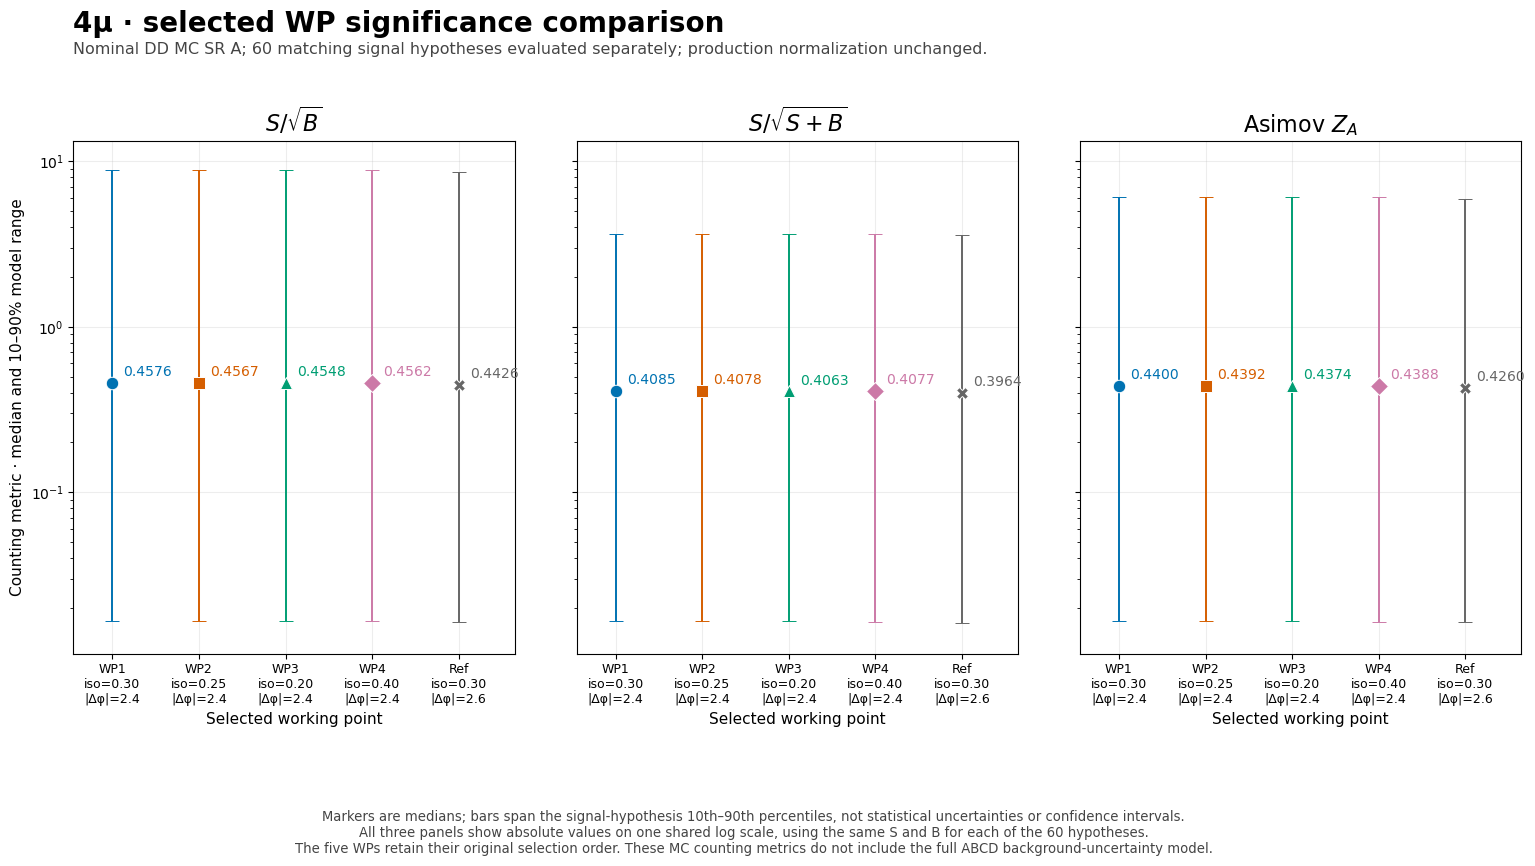

In [3]:
figure_definitions = vr2_focus_figure_definitions()
figures = make_vr2_focus_figures(results, CONFIG)
figure_lookup = {name: figure for figure, name in figures}
assert len(figures) == len(figure_lookup) == 8
for figure, _ in figures:
    plt.close(figure)
display(figure_lookup['significance_comparison'])


## 3.1. DATA: annotated full κ scan

All 154 native threshold points are shown as equal-spaced cells, as in notebooks 01–06. Tick labels give the actual isolation and angle thresholds through iso=2 and |Δφ|=π; zero splits are excluded. Each valid cell is labeled by its κ value. The violet rectangle encloses iso 0.20–0.40 and |Δφ| 2.4–2.8. DATA gates remain masked; there are no selected-WP markers.


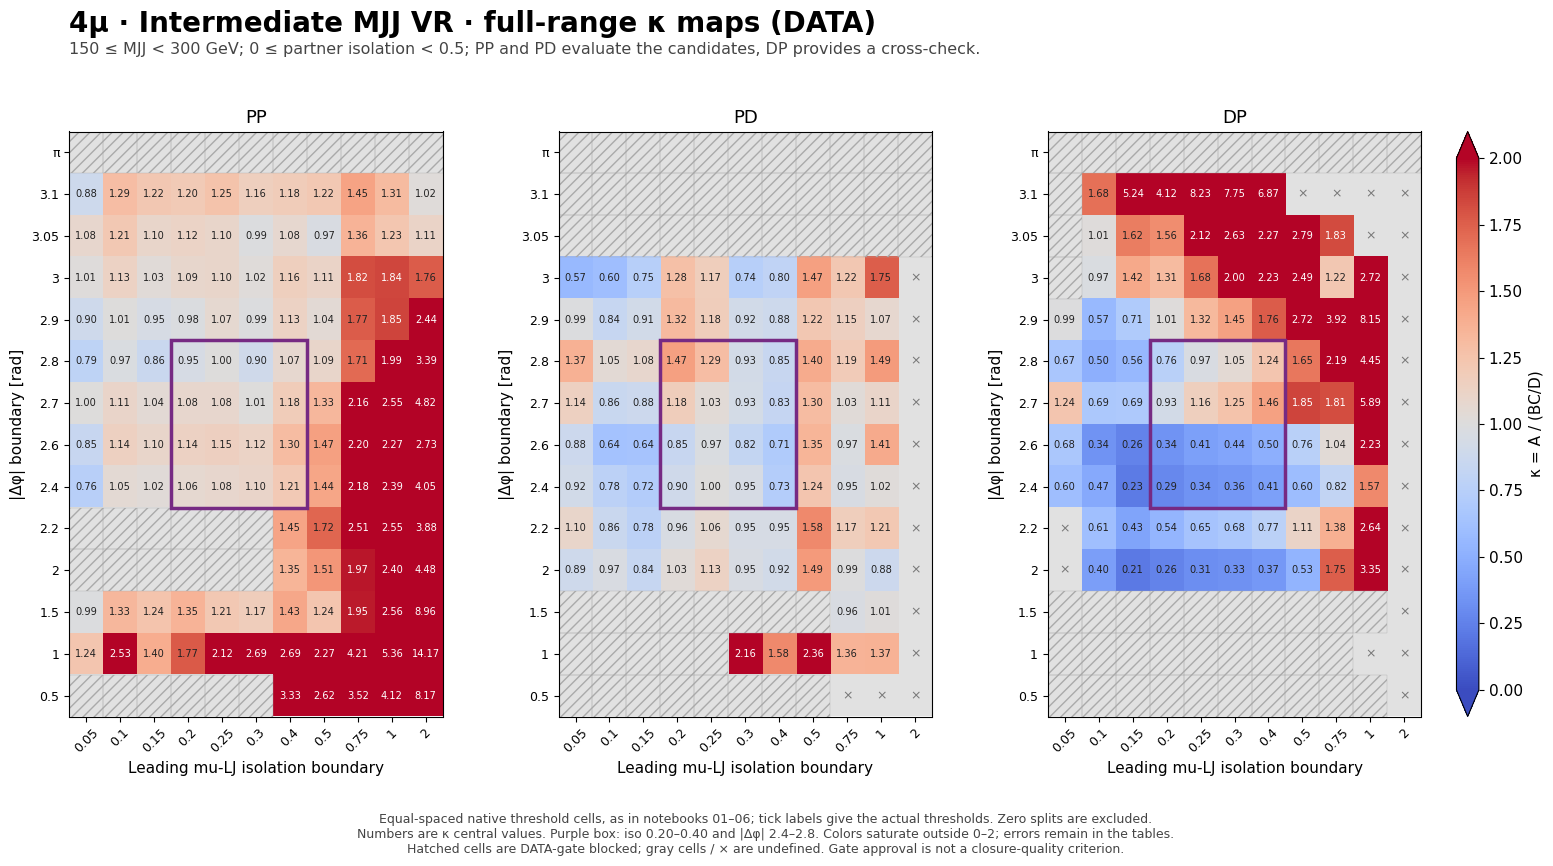

In [4]:
display(figure_lookup['full_data_kappa'])


## 3.2. MC: the same annotated full κ scan

The same threshold-grid display and local rectangle are used for MC. Colors share a κ=1 center and saturate outside 0–2. Numerical labels retain central values outside that range; uncertainties and support flags remain in the front summary and exported table.


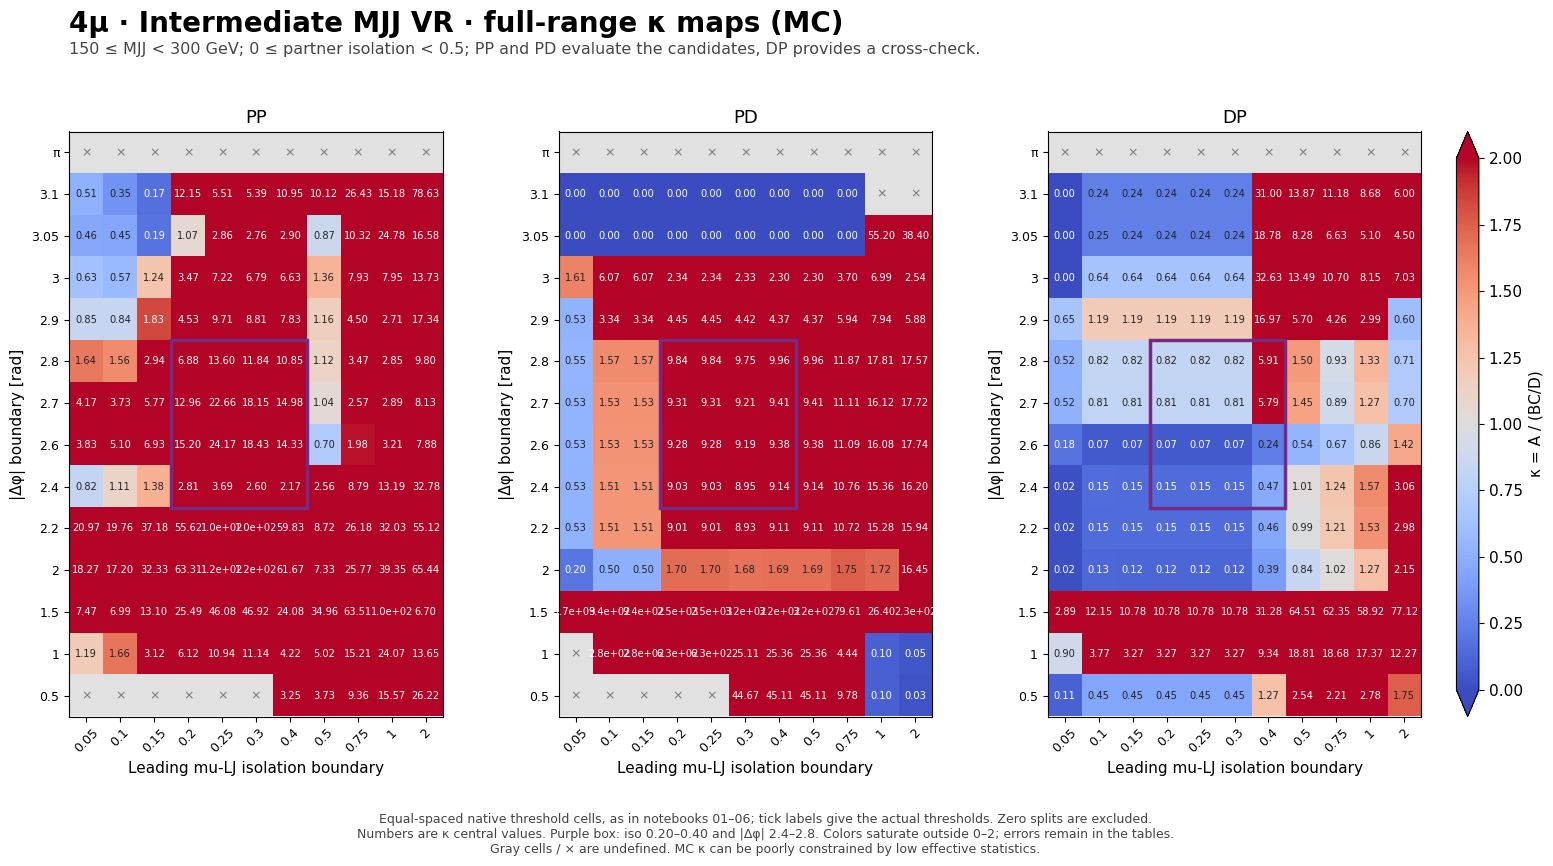

In [5]:
display(figure_lookup['full_mc_kappa'])


## 4. PP and PD evaluated together

Each marker is one selected WP: x is PP DATA κ and y is PD DATA κ, with marginal propagated errors. The (1,1) reference tests closure in both categories. Nearby WPs share events; this view does not define a new fit probability or selection score.


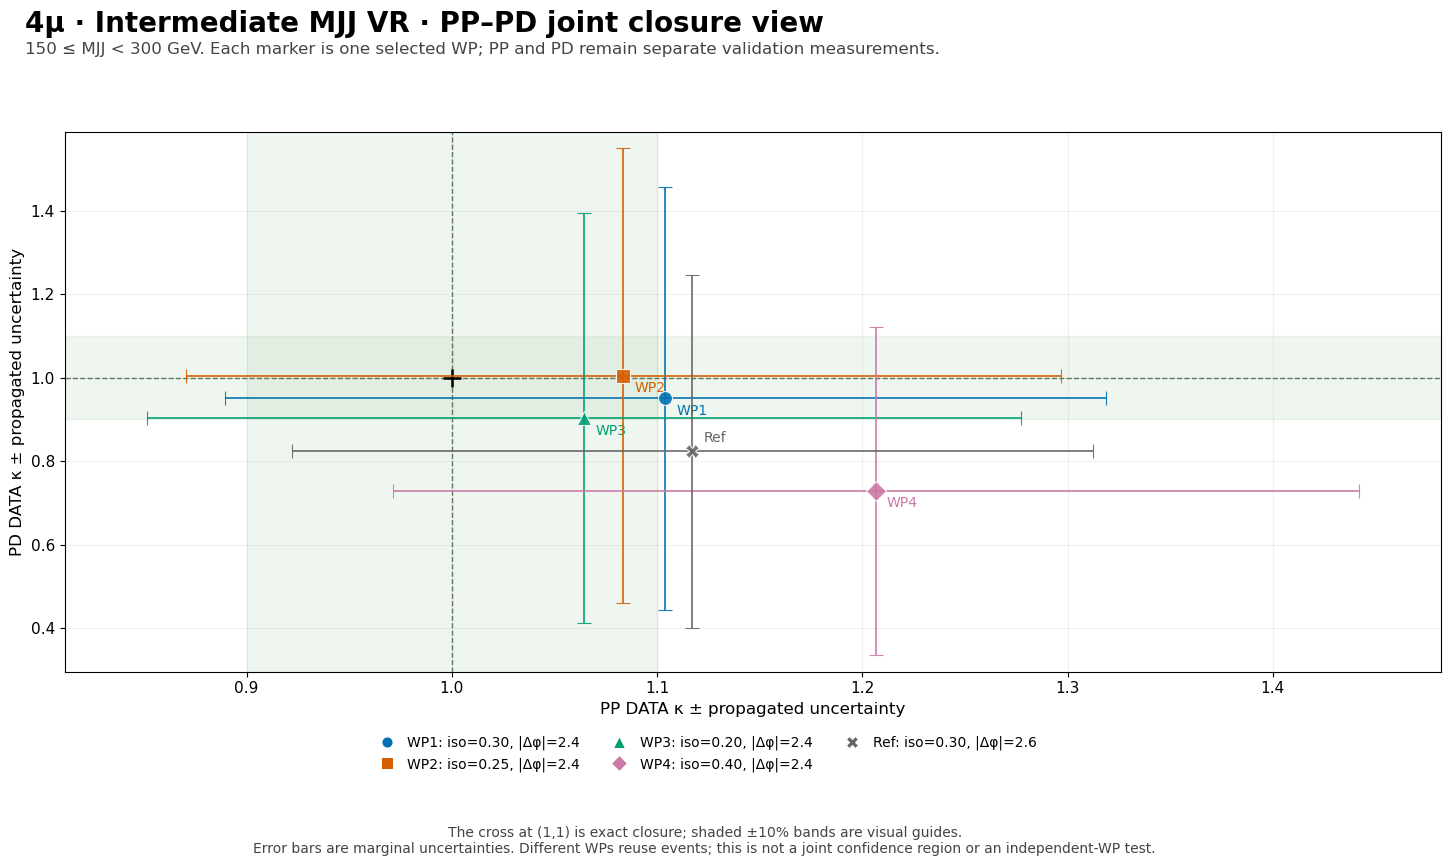

In [6]:
display(figure_lookup['pp_pd_joint'])


## 5. The five selected WPs in PP, PD, and DP

Columns are PP, PD, and DP. Rows show A and BC/D with uncertainties, κ with uncertainties, and the maximum MC S/B over all 120 hypotheses and ABCD regions. Only the selected five appear on the horizontal axes.


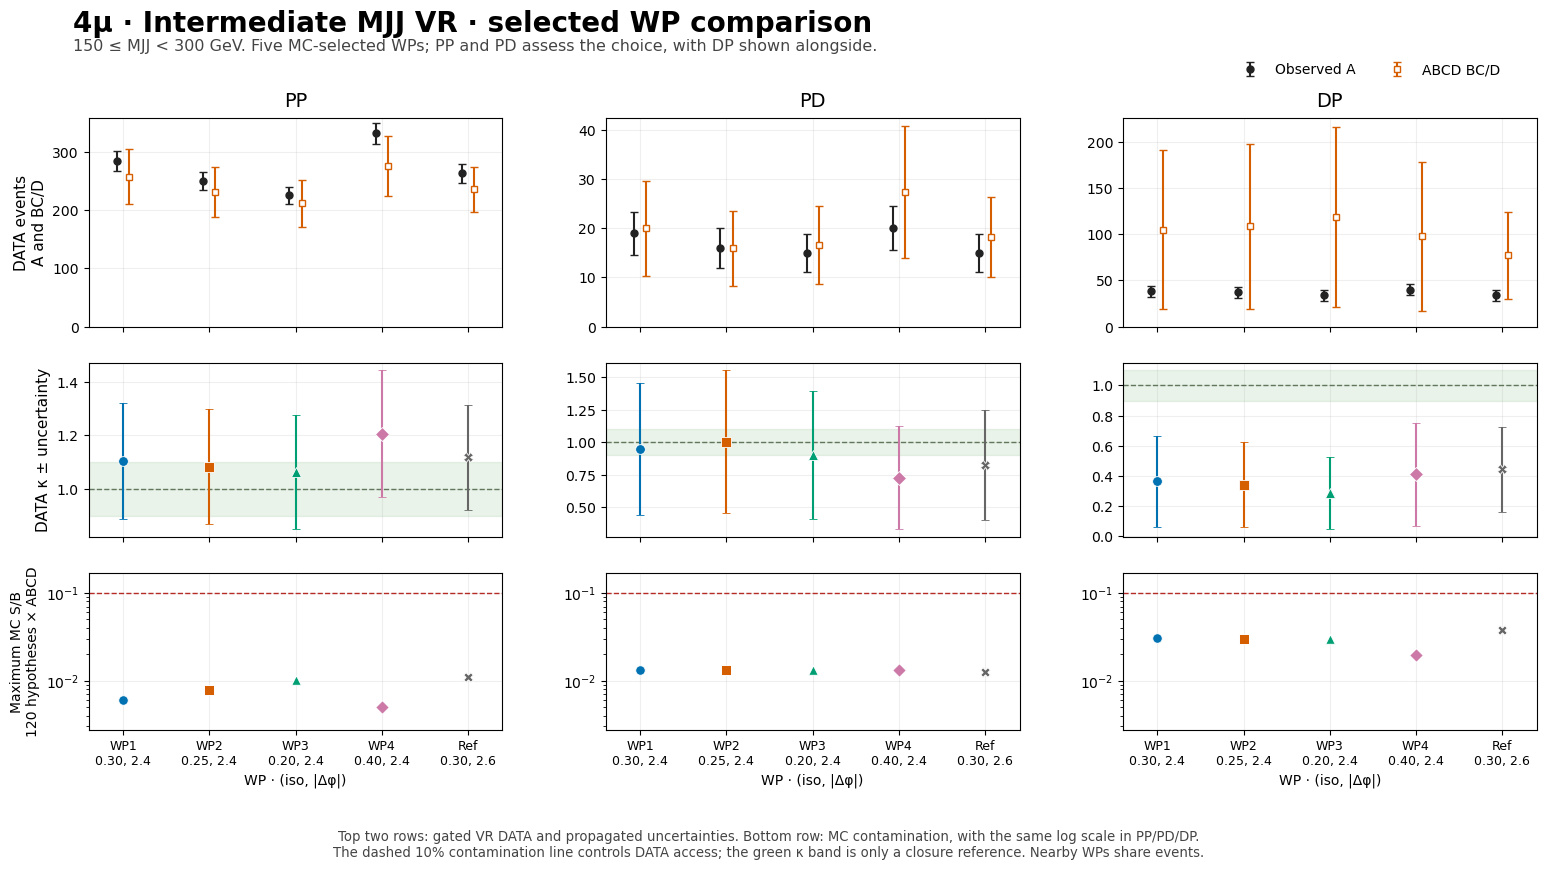

In [7]:
display(figure_lookup['selected_summary'])


## 6. PP: 1D stability comparisons

Display iso 0–1 and |Δφ| 1–3 using only the stored positive native thresholds. Columns scan isolation and angle; rows show yields, κ and contamination. The opposite coordinate is held fixed to a selected WP value. Shared curves are drawn once, and legends occupy dedicated areas outside the panels.


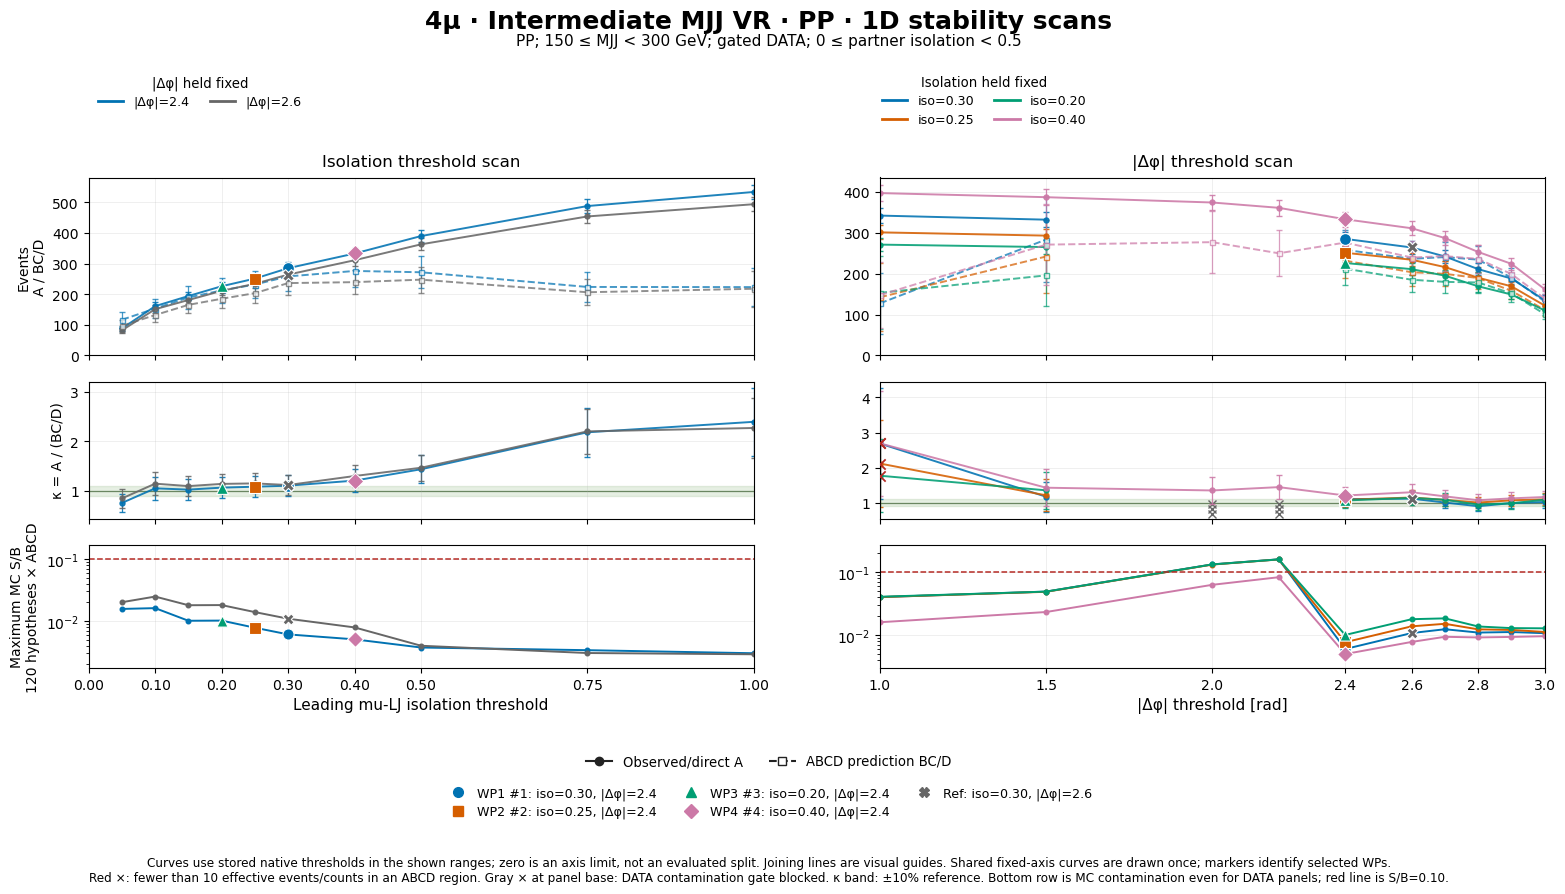

In [8]:
display(figure_lookup['scan_VR2_PP'])


## 7. PD: 1D stability comparisons

Use the same extended ranges and WPs to assess whether the PD closure pattern is stable away from the selected boundaries. DATA-gated points remain gaps in the curves.


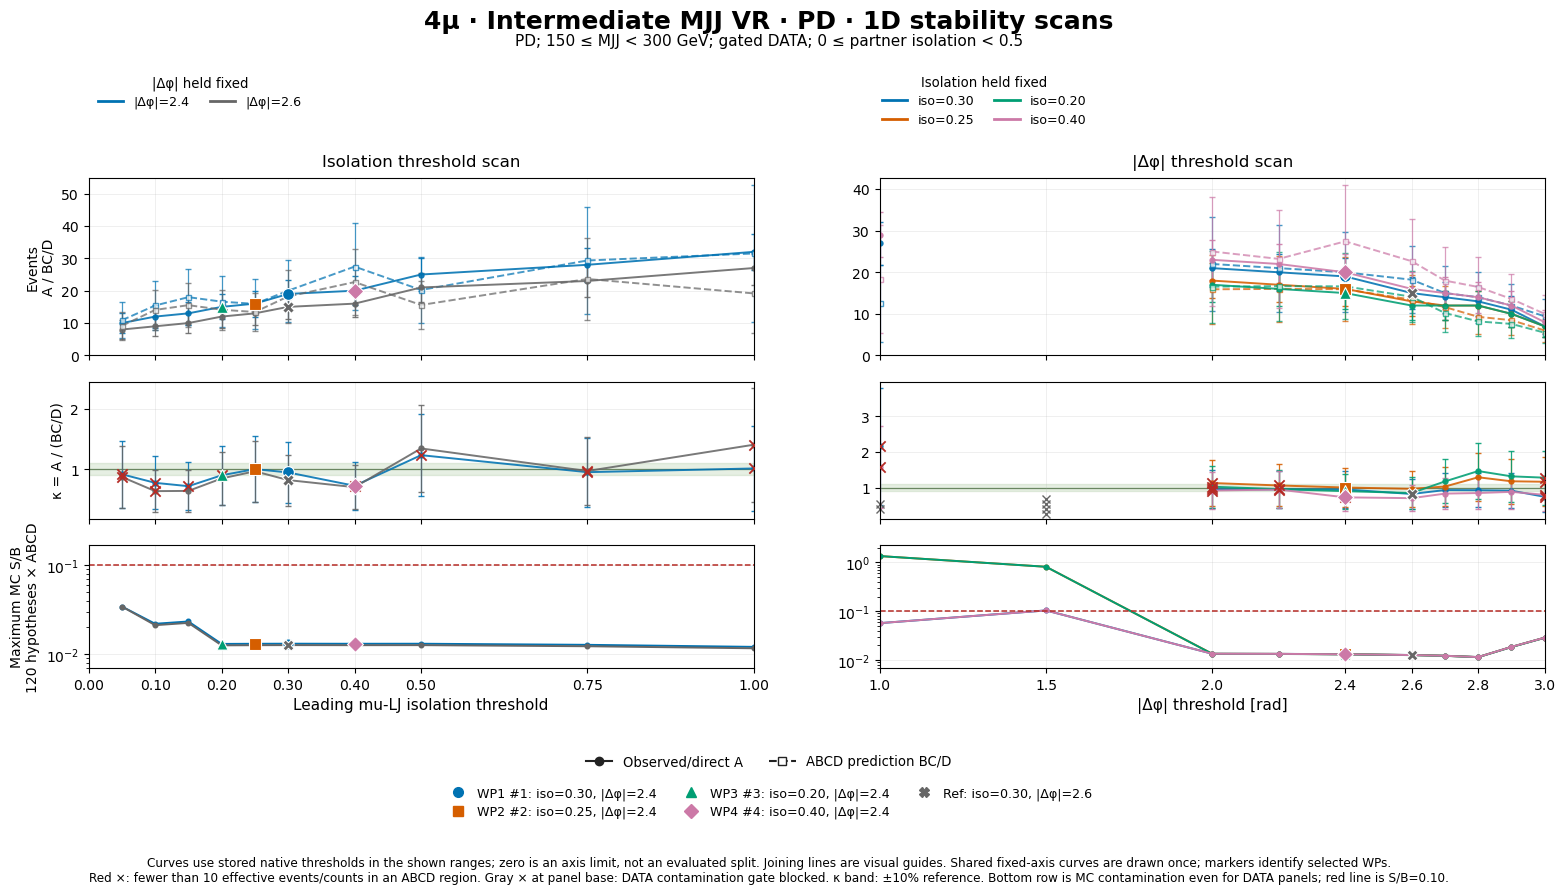

In [9]:
display(figure_lookup['scan_VR2_PD'])


## 8. DP: 1D stability comparisons

DP does not enter candidate selection. The extended scans retain its event counts, larger uncertainties and contamination gates, with the same cuts and marker identities as PP and PD.


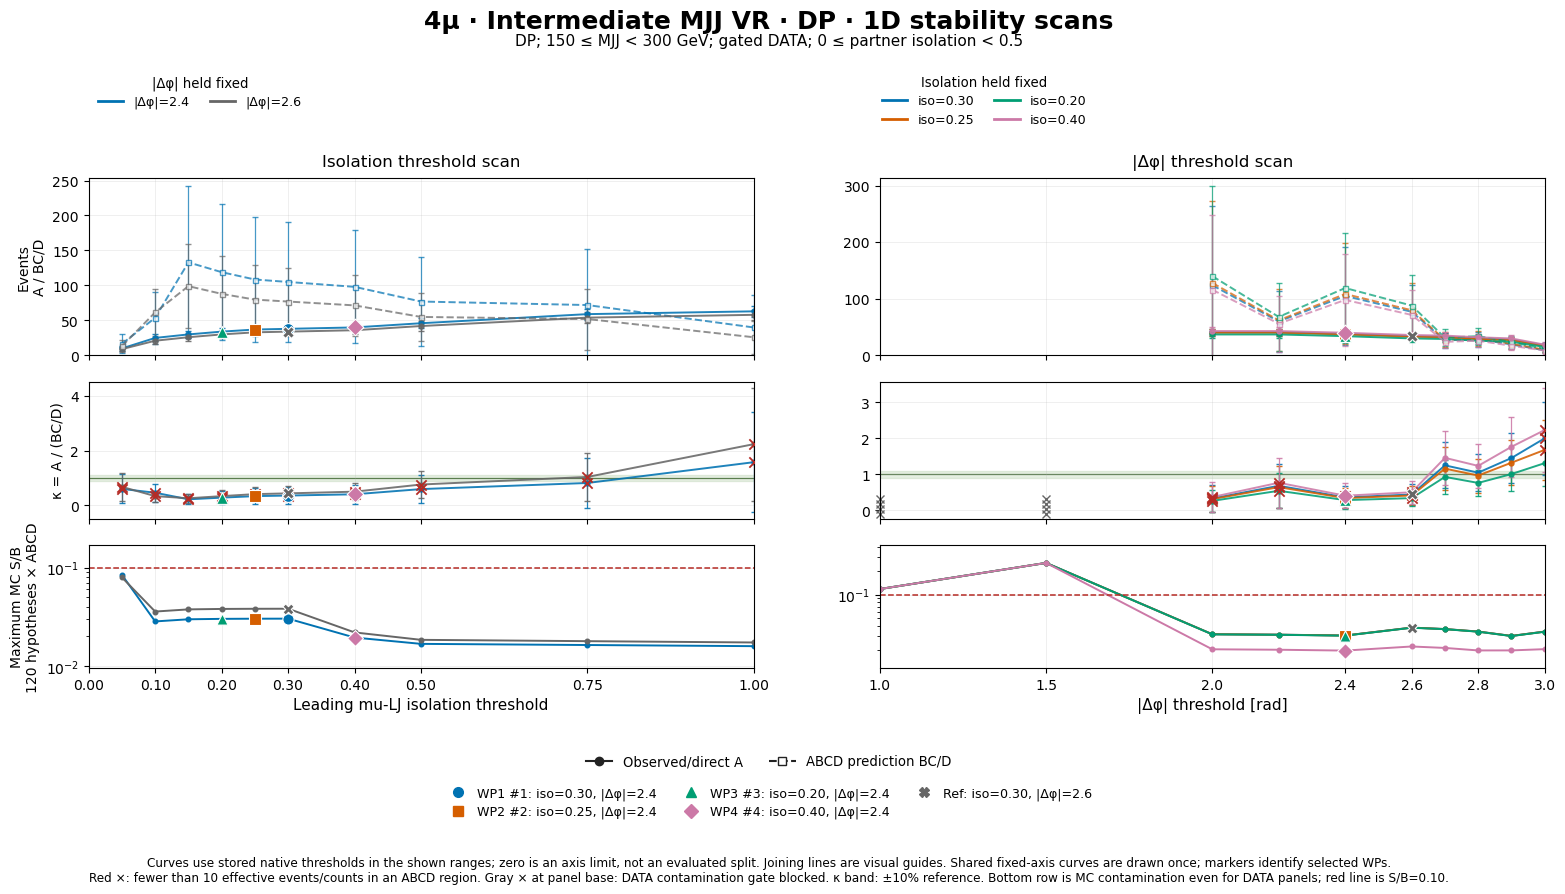

In [10]:
display(figure_lookup['scan_VR2_DP'])


## 9. Checks and numerical outputs

The focused comparison preserves the notebook-04 selections, native boundaries,
production weights, and all-hypothesis contamination gates. The full map is broad;
the candidate pool is local; detailed comparisons show only the five selected points.
The PP/PD κ values and their uncertainties must be read together. A suitable VR
comparison alone does not establish a numerical κ transfer to the nominal SR.


In [11]:
import hashlib
import json
from datetime import datetime, timezone

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
exports = {
    'selected_working_points': tables['working_points'],
    'selected_metrics': tables['ranking'],
    'selected_comparison': selected_table,
    'selected_comprehensive_numeric': summary_numeric,
    'selected_closure': tables['closure'],
    'selected_contamination': tables['purity'],
    'selected_signal_significance': tables['signal_significance'],
    'full_vr2_closure': tables['full_closure'],
    'full_vr2_contamination': tables['full_purity'],
    'candidate_pool_audit': tables['candidate_pool'],
    'figure_definitions': figure_definitions,
    'validation': tables['validation'],
    'input_manifest': tables['input_manifest'],
}
for name, frame in exports.items():
    frame.to_csv(OUTPUT_DIR / f'{name}.csv', index=False)
for figure, name in figures:
    figure.savefig(OUTPUT_DIR / f'{name}.png', dpi=110, facecolor='white')
implementation = {name: hashlib.sha256((NOTEBOOK_DIR / name).read_bytes()).hexdigest()
                  for name in ('abcd_finalize_common.py', 'abcd_finalize_plots.py')}
manifest = {'created_utc': datetime.now(timezone.utc).isoformat(),
            'configuration': CONFIG, 'methodology': results['metadata'],
            'figures': [name for _, name in figures],
            'table_rows': {name: len(frame) for name, frame in exports.items()},
            'implementation_sha256': implementation}
(OUTPUT_DIR / 'manifest.json').write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2, default=str) + chr(10))
validation_display = tables['validation'].copy()
validation_display['scope'] = (validation_display['scope']
    .str.replace('VR2_', 'Intermediate MJJ VR · ', regex=False)
    .str.replace('VR2', 'Intermediate MJJ VR', regex=False))
validation_display['check'] = validation_display['check'].str.replace(
    'VR2', 'Intermediate MJJ VR (150 ≤ MJJ < 300 GeV)', regex=False)
display(validation_display)
display(Markdown(f'[Focused numerical tables and previews]({OUTPUT_DIR.name}/)'))
print(f'Completed: {len(selected)} selected WPs, {len(figures)} figures, Intermediate MJJ VR (150 ≤ MJJ < 300 GeV), PP/PD/DP only.')


,scope,check,passed
0,Intermediate MJJ VR · PP,Complete 154-WP Intermediate MJJ VR (150 ≤ MJJ...,True
1,Intermediate MJJ VR · PD,Complete 154-WP Intermediate MJJ VR (150 ≤ MJJ...,True
2,Intermediate MJJ VR · DP,Complete 154-WP Intermediate MJJ VR (150 ≤ MJJ...,True
3,Intermediate MJJ VR,"Notebook-04 cuts, histogram identity, native b...",True
4,Local,16 unique native candidates; identical 60-mode...,True
5,Displayed,Exactly five ranked WPs; reference is not a fo...,True
6,Evaluation,PP and PD only; DP excluded from both selectio...,True
7,Evaluation,Selected PP/PD DATA retain the existing 120-mo...,True
8,Inputs,Cached tables only; no raw MC/signal/DATA or V...,True
9,SR,Nominal SR input is MC only; no nominal DATA a...,True


[Focused numerical tables and previews](08_4mu_VR2_focused_outputs/)

Completed: 5 selected WPs, 8 figures, Intermediate MJJ VR (150 ≤ MJJ < 300 GeV), PP/PD/DP only.
